# Drug Stores – Store-wise Sales Forecasting
**Business problem:** predict daily `Sales` of every store for the next 1–7 days (batch prediction by Store Id).
**Data:** `Salesdata-DS_DATA.csv` (9 cols, ~1.01 M rows) + `store-DS_DATA.csv` (10 cols, 1,115 stores) | **Training sample:** 100,000 rows
**Metric:** RMSPE (main), RMSE, MAE, R²

### Project structure
| Step | Section | Output |
|---|---|---|
| 1 | Setup | libraries, settings |
| 2 | Load data | merged table |
| 3 | Data cleaning | clean open-store data |
| 4 | EDA | patterns that guide the model |
| 5 | Feature engineering | lag, rolling, promo, holiday features |
| 6 | Train / validation / test split | time-based, 100k sample |
| 7 | Model building | 3 models → tuning → ensemble → calibration |
| 8 | Evaluation | metrics + diagnostic plots |
| 9 | Batch prediction | `predict_batch()` by store id |
| 10 | Save model | `sales_forecast_model.joblib` |




## 1. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, warnings
warnings.filterwarnings('ignore'); sns.set_style('whitegrid')

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, make_scorer
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

SEED, N_SAMPLE, TEST_DAYS, HORIZON = 42, 100_000, 42, 7   # sample size (50k-1 lakh), test weeks, forecast days

## 2. Load Data

In [2]:
sales = pd.read_csv('C:\\Users\\lakshraj computer\\Desktop\\store\\Salesdata-DS DATA.csv', low_memory=False)
store = pd.read_csv('C:\\Users\\lakshraj computer\\Desktop\\store\\store-DS DATA.csv')
df = sales.merge(store, on='Store', how='left')
print('Sales:', sales.shape, '| Store:', store.shape, '| Merged:', df.shape)

Sales: (1017209, 9) | Store: (1115, 10) | Merged: (1017209, 18)


## 3. Data Cleaning

In [3]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df = df.sort_values(['Store', 'Date']).reset_index(drop=True)
df['StateHoliday'] = df['StateHoliday'].astype(str)

# holiday calendar is taken BEFORE removing closed days (stores are closed on holidays)
HOLIDAYS = np.sort(df.loc[df.StateHoliday != '0', 'Date'].unique())

# blanks in competition / Promo2 columns mean "not applicable"
NA_COLS = ['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2SinceWeek', 'Promo2SinceYear']
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(df['CompetitionDistance'].median())
df[NA_COLS] = df[NA_COLS].fillna(0)
df['PromoInterval'] = df['PromoInterval'].fillna('None')

# closed stores always have 0 sales -> model open days only, predict 0 when closed
df = df.dropna(subset=['Open'])
df = df[(df.Open == 1) & (df.Sales > 0)].reset_index(drop=True)
print('Clean shape:', df.shape, '| Dates:', df.Date.min().date(), '->', df.Date.max().date())

Clean shape: (844338, 18) | Dates: 2013-01-01 -> 2015-07-31


## 4. Exploratory Data Analysis

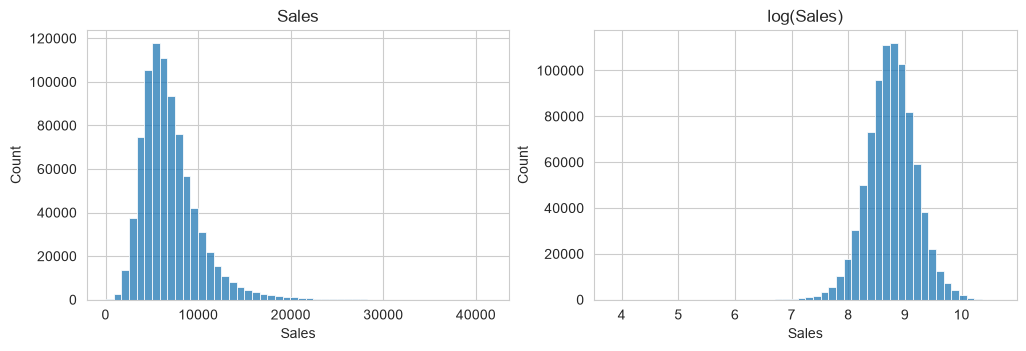

In [4]:
# Why: Sales are right-skewed, so we train on log(Sales) to treat small and big stores fairly.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(df.Sales, bins=50, ax=ax[0]); ax[0].set_title('Sales')
sns.histplot(np.log1p(df.Sales), bins=50, ax=ax[1]); ax[1].set_title('log(Sales)')
plt.show()

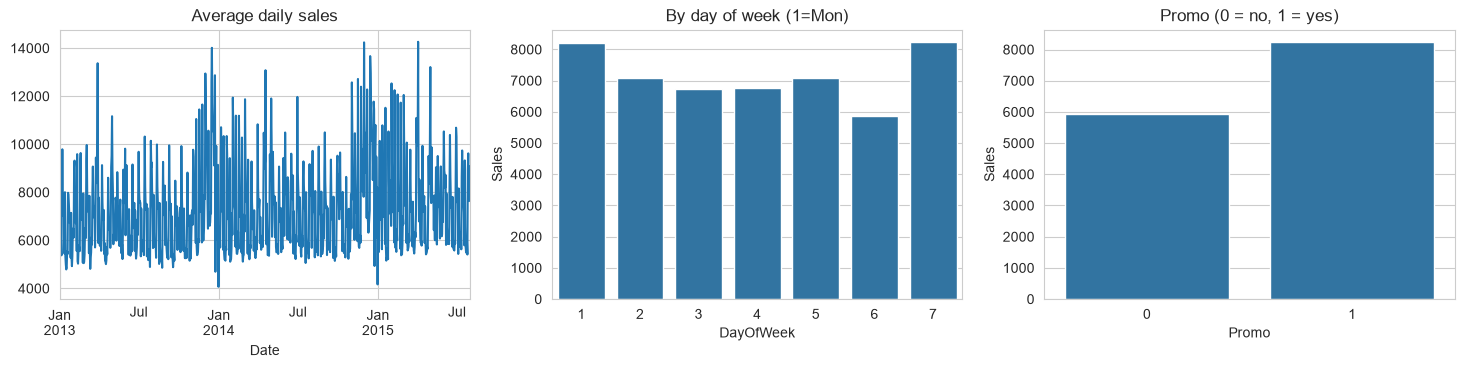

In [5]:
# Why: shows yearly trend, weekly pattern and promo lift, which is why we add calendar, lag and promo features.
fig, ax = plt.subplots(1, 3, figsize=(18, 3.5))
df.groupby('Date').Sales.mean().plot(ax=ax[0], title='Average daily sales')
sns.barplot(data=df, x='DayOfWeek', y='Sales', ax=ax[1], errorbar=None); ax[1].set_title('By day of week (1=Mon)')
sns.barplot(data=df, x='Promo', y='Sales', ax=ax[2], errorbar=None); ax[2].set_title('Promo (0 = no, 1 = yes)')
plt.show()

## 5. Feature Engineering
Only information known **before** the forecast day is used: lags are shifted by 7 days and `Customers` is used only from the past.

In [6]:
MONTH = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',7:'Jul',8:'Aug',9:'Sept',10:'Oct',11:'Nov',12:'Dec'}

def add_features(data, holidays):
    d = data.copy()
    # calendar
    d['DayOfWeek'] = d.Date.dt.dayofweek + 1
    d['Month'], d['Day'], d['WeekOfYear'] = d.Date.dt.month, d.Date.dt.day, d.Date.dt.isocalendar().week.astype(int)
    # competition & Promo2
    year = d.Date.dt.year
    comp = (year - d.CompetitionOpenSinceYear) * 12 + (d.Month - d.CompetitionOpenSinceMonth)
    d['CompetitionOpenMonths'] = np.where(d.CompetitionOpenSinceYear > 0, comp, 0).clip(0)
    p2 = (year - d.Promo2SinceYear) * 52 + (d.WeekOfYear - d.Promo2SinceWeek)
    d['Promo2Weeks']   = np.where(d.Promo2 == 1, p2, 0).clip(0)
    d['IsPromo2Month'] = [int(m in iv) for m, iv in zip(d.Month.map(MONTH), d.PromoInterval)]
    # holiday proximity (capped at 30 days)
    dates = d.Date.values
    nxt = np.searchsorted(holidays, dates, side='left')
    prv = np.searchsorted(holidays, dates, side='right') - 1
    d['DaysToHoliday']    = np.where(nxt < len(holidays), (holidays[nxt.clip(max=len(holidays)-1)] - dates) / np.timedelta64(1, 'D'), 30).clip(max=30)
    d['DaysSinceHoliday'] = np.where(prv >= 0, (dates - holidays[prv.clip(min=0)]) / np.timedelta64(1, 'D'), 30).clip(max=30)

    # Store x Date tables -> lags and rolling means
    table = lambda col: d.pivot(index='Date', columns='Store', values=col)
    wide  = table('Sales'); wide = wide.reindex(pd.date_range(wide.index.min(), wide.index.max()))
    promo, cust = table('Promo').reindex(wide.index), table('Customers').reindex(wide.index)
    base, promo7 = wide.shift(HORIZON), promo.shift(HORIZON)
    feats = {
        'Lag_7': base, 'Lag_14': wide.shift(14), 'Lag_21': wide.shift(21), 'Lag_28': wide.shift(28),
        'Lag_364': wide.shift(364),                                                    # same day last year
        'Roll_7': base.rolling(7, min_periods=1).mean(), 'Roll_28': base.rolling(28, min_periods=1).mean(),
        'Roll_91': base.rolling(91, min_periods=1).mean(), 'Std_28': base.rolling(28, min_periods=2).std(),
        'PromoLag_7': promo7,
        'PromoMean_28':   base.where(promo7 == 1).rolling(28, min_periods=1).mean(),   # average on promo days
        'NoPromoMean_28': base.where(promo7 == 0).rolling(28, min_periods=1).mean(),   # average on non-promo days
        'Cust_Lag_7': cust.shift(HORIZON), 'Cust_Roll_28': cust.shift(HORIZON).rolling(28, min_periods=1).mean(),
    }
    lag_df = None
    for name, w in feats.items():
        long = w.rename_axis('Date').reset_index().melt('Date', var_name='Store', value_name=name)
        lag_df = long if lag_df is None else lag_df.assign(**{name: long[name].values})
    d = d.merge(lag_df, on=['Date', 'Store'], how='left')

    # combined features
    d['Roll_28_Promo'] = np.where(d.Promo == 1, d.PromoMean_28, d.NoPromoMean_28)   # expected sales for today's promo status
    d['Roll_28_Promo'] = d['Roll_28_Promo'].fillna(d.Roll_28)
    d['SalesPerCust']  = d.Roll_28 / d.Cust_Roll_28
    d['WeekdayMean_4'] = d[['Lag_7', 'Lag_14', 'Lag_21', 'Lag_28']].mean(axis=1)
    return d

data = add_features(df, HOLIDAYS)

NUM = ['DayOfWeek','Promo','SchoolHoliday','CompetitionDistance','CompetitionOpenMonths','Promo2','Promo2Weeks','IsPromo2Month',
       'Month','Day','WeekOfYear','DaysToHoliday','DaysSinceHoliday',
       'Lag_7','Lag_14','Lag_21','Lag_28','Lag_364','Roll_7','Roll_28','Roll_91','Std_28','PromoLag_7',
       'PromoMean_28','NoPromoMean_28','Cust_Lag_7','Cust_Roll_28','Roll_28_Promo','SalesPerCust','WeekdayMean_4']
CAT = ['StateHoliday','StoreType','Assortment','PromoInterval']
FEATURES = NUM + CAT

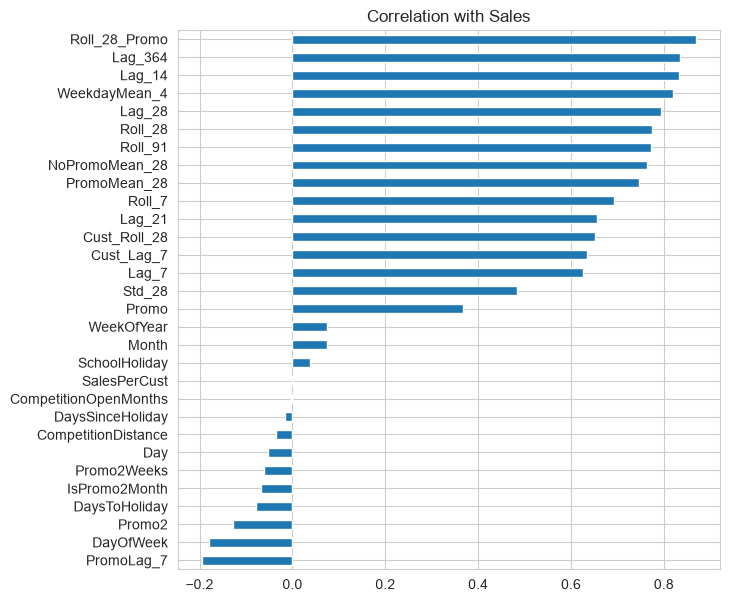

In [7]:
# Why: confirms the new lag / rolling features are the strongest predictors of Sales.
data[NUM].corrwith(data.Sales).sort_values().plot.barh(figsize=(7, 7), title='Correlation with Sales')
plt.show()

## 6. Time-based Split & 100k Sample
Test = last 6 weeks. Validation = the 6 weeks before that. Training rows are sampled from the past, with newer dates more likely to be picked.

In [8]:
cutoff = data.Date.max() - pd.Timedelta(days=TEST_DAYS)
past, test = data[data.Date <= cutoff], data[data.Date > cutoff]

age = (past.Date - past.Date.min()).dt.days
train = past.sample(N_SAMPLE, weights=((age + 30) / age.max()) ** 2, random_state=SEED).sort_values('Date')

X_train, y_train = train[FEATURES], train.Sales
X_test,  y_test  = test[FEATURES],  test.Sales

is_val = (train.Date > cutoff - pd.Timedelta(days=TEST_DAYS)).values            # validation window inside the training period
cv = [(np.where(~is_val)[0], np.where(is_val)[0])]
print('Fit rows:', (~is_val).sum(), '| Validation rows:', is_val.sum(), '| Test rows:', len(test))

Fit rows: 87633 | Validation rows: 12367 | Test rows: 40282


## 7. Model Building
Categories → ordinal codes. Target = `log(Sales)`, which is close to what RMSPE measures (relative error).

In [9]:
prep = ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), CAT)], remainder='passthrough')

def make_model(regressor):
    pipe = Pipeline([('prep', prep), ('model', regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.sqrt(np.mean(((y_true - y_pred) / y_true) ** 2)) * 100

def evaluate(y_true, y_pred):
    return {'RMSPE %': rmspe(y_true, y_pred), 'RMSE': root_mean_squared_error(y_true, y_pred),
            'MAE': mean_absolute_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}

In [10]:
LGBM_PARAMS = dict(n_estimators=1000, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.7, reg_lambda=5, random_state=SEED, verbose=-1)
xgb  = XGBRegressor(tree_method='hist', n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8,
                    colsample_bytree=0.7, reg_lambda=5, random_state=SEED)
hist = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=63, l2_regularization=5, random_state=SEED)

models = {'LightGBM': LGBMRegressor(**LGBM_PARAMS), 'XGBoost': xgb, 'HistGB': hist,
          'Ensemble': VotingRegressor([('lgbm', LGBMRegressor(**LGBM_PARAMS)), ('xgb', xgb), ('hist', hist)])}

scoring = {'rmspe': make_scorer(rmspe, greater_is_better=False), 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}
rows = []
for name, reg in models.items():
    s = cross_validate(make_model(reg), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name, 'val_rmspe %': -s['test_rmspe'][0], 'val_rmse': -s['test_rmse'][0], 'val_r2': s['test_r2'][0]})
val_results = pd.DataFrame(rows).sort_values('val_rmspe %').reset_index(drop=True)
val_results.round(3)

,model,val_rmspe %,val_rmse,val_r2
0,Ensemble,11.478,831.676,0.923
1,XGBoost,11.511,830.884,0.923
2,LightGBM,11.540,839.674,0.922
3,HistGB,11.707,851.545,0.920


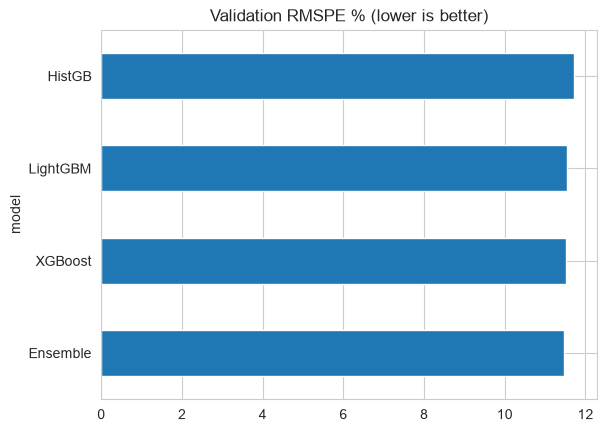

In [11]:
# Why: shows the ensemble has the lowest validation error, so it is the model we ship.
val_results.set_index('model')['val_rmspe %'].plot.barh(title='Validation RMSPE % (lower is better)')
plt.show()

In [12]:
# Tune LightGBM (random search on the validation window)
p = 'regressor__model__'
search = RandomizedSearchCV(make_model(LGBMRegressor(**LGBM_PARAMS)),
    {p+'learning_rate': [0.03, 0.05, 0.1], p+'num_leaves': [31, 63, 127],
     p+'min_child_samples': [20, 50, 100], p+'colsample_bytree': [0.5, 0.7, 0.9]},
    n_iter=8, cv=cv, scoring=make_scorer(rmspe, greater_is_better=False), random_state=SEED).fit(X_train, y_train)
best = {k.replace(p, ''): v for k, v in search.best_params_.items()}
print('Best params:', best, '| Validation RMSPE: %.2f %%' % -search.best_score_)

# Final ensemble = tuned LightGBM + XGBoost + HistGB
ensemble = make_model(VotingRegressor([('lgbm', LGBMRegressor(**{**LGBM_PARAMS, **best})), ('xgb', xgb), ('hist', hist)]))

# Calibration: one shrink factor k that minimises RMSPE (fitted on older rows, checked on the validation window)
m = clone(ensemble).fit(X_train[~is_val], y_train[~is_val])
r = m.predict(X_train[is_val]) / y_train[is_val].values
k = r.sum() / (r ** 2).sum()
print('Calibration factor k = %.4f' % k)

final_model = ensemble.fit(X_train, y_train)
def final_predict(X): return k * final_model.predict(X)

Best params: {'num_leaves': 63, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.5} | Validation RMSPE: 11.44 %
Calibration factor k = 0.9909


## 8. Evaluation on the last 6 unseen weeks

In [13]:
pred_test = final_predict(X_test)
pred_base = test.Lag_14.fillna(test.Roll_28)       # baseline: same weekday 2 weeks ago (promos alternate weekly)

pd.DataFrame({'Baseline (same weekday 2 weeks ago)': evaluate(y_test, pred_base),
              'Final model (test)': evaluate(y_test, pred_test)}).T.round(3)

,RMSPE %,RMSE,MAE,R2
Baseline (same weekday 2 weeks ago),15.646,1171.195,801.230,0.853
Final model (test),11.152,838.658,562.123,0.925


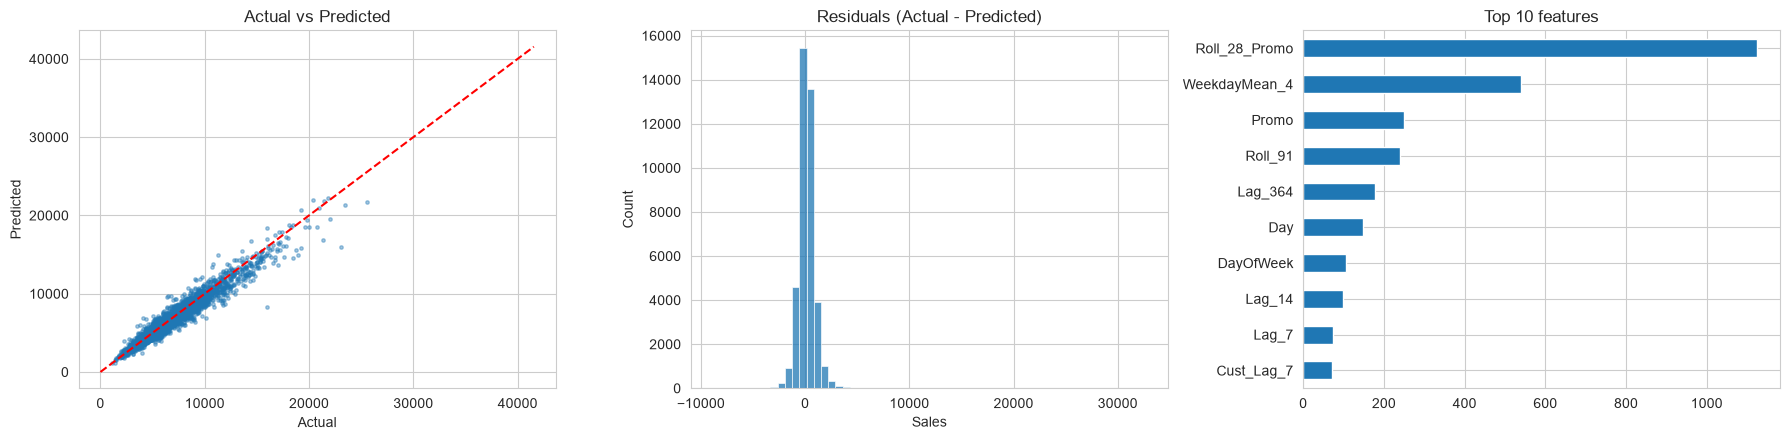

In [14]:
# Why: points near the red line = accurate forecasts; centred residuals = no bias; importance shows what drives sales.
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
idx = np.random.RandomState(SEED).choice(len(y_test), 3000, replace=False)
ax[0].scatter(y_test.values[idx], pred_test[idx], s=6, alpha=.4); ax[0].plot([0, y_test.max()], [0, y_test.max()], 'r--')
ax[0].set_title('Actual vs Predicted'); ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted')
sns.histplot(y_test - pred_test, bins=60, ax=ax[1]); ax[1].set_title('Residuals (Actual - Predicted)')
imp = permutation_importance(final_model, X_test.iloc[idx], y_test.iloc[idx], n_repeats=3, random_state=SEED,
                             scoring='neg_root_mean_squared_error')
pd.Series(imp.importances_mean, index=FEATURES).sort_values().tail(10).plot.barh(ax=ax[2], title='Top 10 features')
plt.tight_layout(); plt.show()

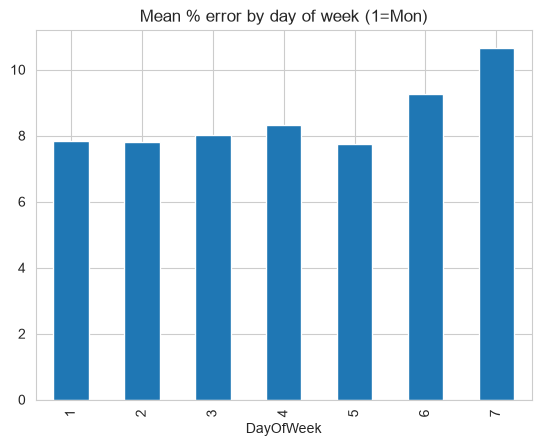

In [15]:
# Why: shows where the model is weakest, so we know what to improve next.
ape = (y_test - pred_test).abs() / y_test * 100
ape.groupby(test.DayOfWeek).mean().plot.bar(title='Mean % error by day of week (1=Mon)')
plt.show()

## 9. Batch Prediction by Store Id
`predict_batch(store_ids, start_date, days)` forecasts one or many stores for 1–7 days (up to 7 days after the last date in the data).
Promo is assumed *same as 2 weeks ago* (promos alternate weekly); open days and school holidays *same as last week*. Pass `future_info` (`Store, Date, Promo, SchoolHoliday, StateHoliday, Open`) if the real calendar is known.

In [16]:
LAST_DATE = df.Date.max()

def predict_batch(store_ids, start_date, days=1, future_info=None):
    store_ids = list(np.atleast_1d(store_ids)); start = pd.Timestamp(start_date)
    if days > HORIZON or start + pd.Timedelta(days=days - 1) > LAST_DATE + pd.Timedelta(days=HORIZON):
        raise ValueError(f'Forecast must be <= {HORIZON} days and end by {(LAST_DATE + pd.Timedelta(days=HORIZON)).date()}')

    hist = df[df.Store.isin(store_ids) & (df.Date >= start - pd.Timedelta(days=400)) & (df.Date < start)]
    fut = pd.DataFrame([(s, d) for s in store_ids for d in pd.date_range(start, periods=days)], columns=['Store', 'Date'])
    fut = fut.merge(store, on='Store', how='left').assign(StateHoliday='0')
    fut['PromoInterval'] = fut['PromoInterval'].fillna('None')
    fut[['CompetitionDistance'] + NA_COLS] = fut[['CompetitionDistance'] + NA_COLS].fillna(0)

    if future_info is None:     # Promo = 14 days ago; Open / SchoolHoliday = 7 days ago
        promo14 = hist[['Store', 'Date', 'Promo']].assign(Date=lambda x: x.Date + pd.Timedelta(days=14))
        wk7     = hist[['Store', 'Date', 'SchoolHoliday']].assign(Date=lambda x: x.Date + pd.Timedelta(days=7), Open=1)
        fut = fut.merge(promo14, on=['Store', 'Date'], how='left').merge(wk7, on=['Store', 'Date'], how='left')
        fut = fut.fillna({'Promo': 0, 'SchoolHoliday': 0, 'Open': 0})
    else:
        fut = fut.drop(columns='StateHoliday').merge(future_info, on=['Store', 'Date'], how='left')
        fut['StateHoliday'] = fut['StateHoliday'].astype(str)

    hol = np.union1d(HOLIDAYS, fut.loc[fut.StateHoliday != '0', 'Date'].values)
    feats = add_features(pd.concat([hist, fut], ignore_index=True), hol)
    feats = feats[feats.Date >= start].copy()
    feats['PredictedSales'] = np.where(feats.Open == 1, final_predict(feats[FEATURES]), 0).round(0)
    return feats[['Store', 'Date', 'DayOfWeek', 'PredictedSales']].sort_values(['Store', 'Date']).reset_index(drop=True)

In [17]:
print(predict_batch(1, '2015-08-01', days=1))          # one store, one day

predict_batch([1, 2, 3, 4, 5], '2015-08-01', days=7).pivot(index='Date', columns='Store', values='PredictedSales')   # many stores, 7 days

  Store       Date  DayOfWeek  PredictedSales
0     1 2015-08-01          6          4510.0


Store,1,2,3,4,5
Date,,,,,
2015-08-01,4510.0,3386.0,4427.0,10404.0,2067.0
2015-08-02,0.0,0.0,0.0,0.0,0.0
2015-08-03,4399.0,4580.0,6449.0,10352.0,4505.0
2015-08-04,3873.0,4321.0,6328.0,9240.0,4146.0
2015-08-05,3705.0,4758.0,6054.0,8974.0,4207.0
2015-08-06,3756.0,4065.0,6188.0,8770.0,3853.0
2015-08-07,3878.0,4213.0,5958.0,9579.0,3941.0


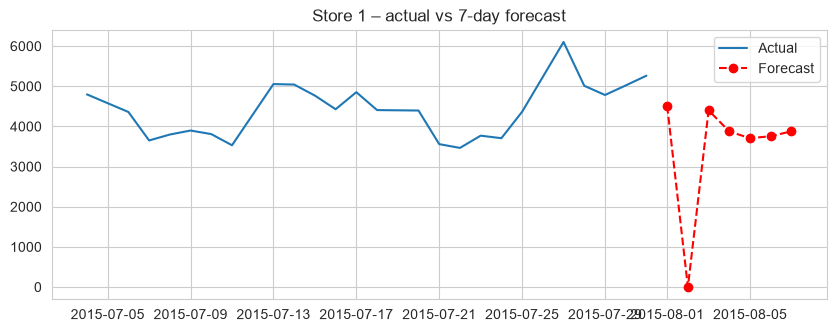

In [18]:
# Why: business view - last 4 weeks of actual sales next to the 7-day forecast for one store (0 = store closed).
fc = predict_batch(1, '2015-08-01', days=7).set_index('Date').PredictedSales
actual = df[(df.Store == 1) & (df.Date >= '2015-07-04')].set_index('Date').Sales
plt.figure(figsize=(10, 3.5)); plt.plot(actual, label='Actual'); plt.plot(fc, 'r--o', label='Forecast')
plt.title('Store 1 – actual vs 7-day forecast'); plt.legend(); plt.show()

## 10. Save Model

In [19]:
joblib.dump({'model': final_model, 'k': k, 'features': FEATURES, 'holidays': HOLIDAYS}, 'sales_forecast_model.joblib')

['sales_forecast_model.joblib']

In [21]:
import os, sklearn, lightgbm, xgboost
os.makedirs('artifacts', exist_ok=True)
LAST_DATE = df.Date.max()
 
# 1) model bundle (model + calibration factor + feature list + holiday calendar + last date in data)
joblib.dump({'model': final_model, 'k': k, 'features': FEATURES, 'holidays': HOLIDAYS, 'last_date': LAST_DATE},
            'artifacts/sales_forecast_model.joblib', compress=3)
 
# 2) recent cleaned history (the lag features need ~400 days; keep 450 to be safe)
hist_df = df[df.Date >= LAST_DATE - pd.Timedelta(days=450)]
try:
    hist_df.to_parquet('artifacts/history.parquet', index=False)
except ImportError:                      # pyarrow not installed -> fall back to pickle
    hist_df.to_pickle('artifacts/history.pkl')
 
# 3) store master table
store.to_csv('artifacts/store.csv', index=False)
 
# 4) pin the exact library versions used for training (a pickled model must be loaded with the same versions)
with open('requirements.txt', 'w') as f:
    f.write(f"streamlit>=1.50\nnumpy=={np.__version__}\npandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\n"
            f"lightgbm=={lightgbm.__version__}\nxgboost=={xgboost.__version__}\njoblib=={joblib.__version__}\n")
print('Saved to ./artifacts  and  requirements.txt')

Saved to ./artifacts  and  requirements.txt
